In [84]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax.numpy as jnp
import matplotlib.pyplot as plt
import scienceplots

import Germany
from SIR import *

plt.style.use([
    'science',
    #'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

In [85]:
# R0 = 12-18
# contagious period ~ 8 days
p = Parameters(alpha=1/8, beta=15/8, gamma=1 - 0.6**(1/365), W=Germany.OD_matrix, quarantine_factor=0.9)
term = ODETerm(f)
solver = Tsit5()

y0 = Germany.make_initial_condition()

In [77]:
t0 = 0.0
t1 = 100.0
dt0 = 1.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0))

In [78]:
solution = diffeqsolve(term, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)

In [79]:
ts = solution.ts
ys = solution.ys.reshape((-1, N_VARS, p.n_cities)) # type: ignore

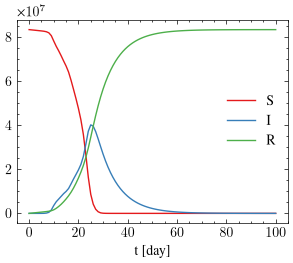

In [86]:
# plot S, I, R reduced over counties
plt.figure()
S_reduced = jnp.sum(ys[:, 0, :], axis=1)
I_reduced = jnp.sum(ys[:, 1, :], axis=1)
R_reduced = jnp.sum(ys[:, 2, :], axis=1)
plt.plot(ts, S_reduced, label="S")
plt.plot(ts, I_reduced, label="I")
plt.plot(ts, R_reduced, label="R")
plt.xlabel("t [day]")
plt.legend()
plt.savefig("../figures/SIR.pdf")

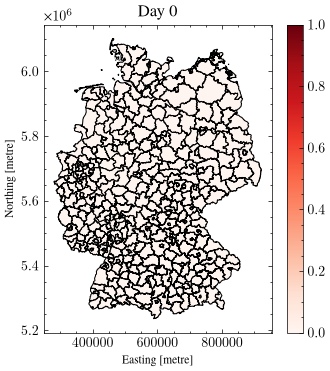

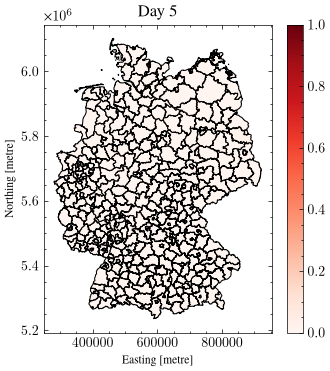

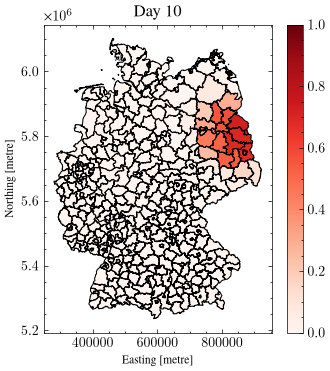

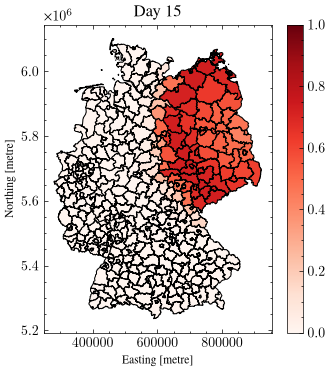

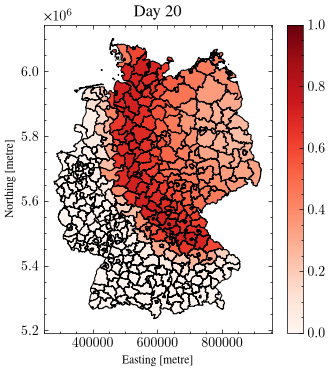

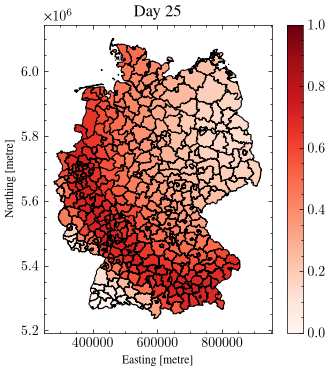

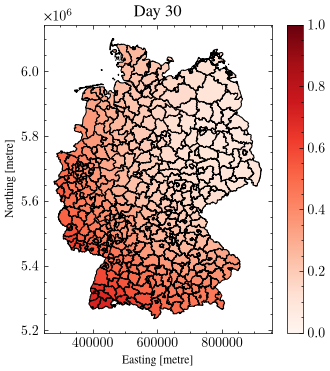

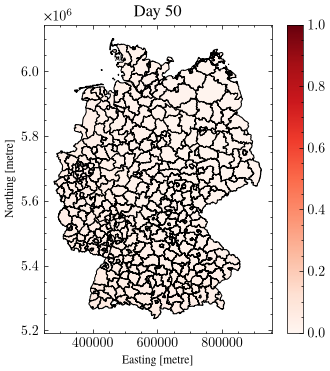

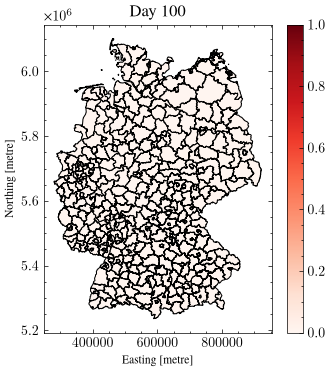

In [81]:
# plot map of infected individuals day 0, 50, 100, ..., 300
for day in [0, 5, 10, 15, 20, 25, 30, 50, 100]:
    gdf = Germany.gdf.copy()
    plt.figure(figsize=(4,4))
    plt.title(f"Day {day}")
    S, I, R = ys[day, :, :]
    gdf['infected'] = I / (S + I + R)
    gdf.plot(column='infected', ax=plt.gca(), legend=True, cmap='Reds', edgecolor='black', linewidth=0.75, vmin=0, vmax=1)
    plt.show()